<a href="https://colab.research.google.com/github/M4uroM4rcos/segmentacao-clientes-kmeans/blob/main/segmentacao_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentação de clientes de um atacadista com K-Means

## Pergunta do projeto
Que tipos de cliente existem em um atacadista, a partir do que eles compram, e o que fazer com cada grupo?

## Dados
Conjunto **Wholesale customers**, do UCI Machine Learning Repository: 440 clientes, com o gasto anual em 6 categorias de produto (Fresh, Milk, Grocery, Frozen, Detergents_Paper e Delicassen), além do canal (1 = hotel/restaurante/café, 2 = varejo) e da região.

Fonte: Cardoso, M. (2013). Wholesale customers [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5030X. Licença: CC BY 4.0.

## Método
1. Exploração dos dados e consultas SQL (SQLite).
2. Transformação logarítmica e padronização dos gastos.
3. Escolha do número de grupos com o método do cotovelo e a silhueta.
4. Agrupamento com K-Means (k = 3) e interpretação dos grupos.

In [16]:
!pip install ucimlrepo

In [17]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

dataset = fetch_ucirepo(id=292)
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

In [18]:
print(df.shape)
df.head()

(440, 8)


,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Region
0,2,12669,9656,7561,214,2674,1338,3
1,2,7057,9810,9568,1762,3293,1776,3
2,2,6353,8808,7684,2405,3516,7844,3
3,1,13265,1196,4221,6404,507,1788,3
4,2,22615,5410,7198,3915,1777,5185,3


In [19]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Fresh             440 non-null    int64
 2   Milk              440 non-null    int64
 3   Grocery           440 non-null    int64
 4   Frozen            440 non-null    int64
 5   Detergents_Paper  440 non-null    int64
 6   Delicassen        440 non-null    int64
 7   Region            440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Region
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455,2.543182
std,0.468052,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937,0.774272
min,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000,1.000000
25%,1.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000,2.000000
50%,1.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000,3.000000
75%,2.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000,3.000000
max,2.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000,3.000000


In [20]:
import sqlite3

conn = sqlite3.connect("clientes.db")
df.to_sql("clientes", conn, if_exists="replace", index=False)

consulta = """
SELECT Channel,
       COUNT(*) AS total_clientes,
       ROUND(AVG(Fresh)) AS media_fresh,
       ROUND(AVG(Grocery)) AS media_grocery,
       ROUND(AVG(Milk)) AS media_milk
FROM clientes
GROUP BY Channel
"""
pd.read_sql(consulta, conn)

,Channel,total_clientes,media_fresh,media_grocery,media_milk
0,1,298,13476.0,3962.0,3452.0
1,2,142,8904.0,16323.0,10717.0


In [21]:
import numpy as np
from sklearn.preprocessing import StandardScaler

colunas = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X = np.log1p(df[colunas])
X_pad = StandardScaler().fit_transform(X)

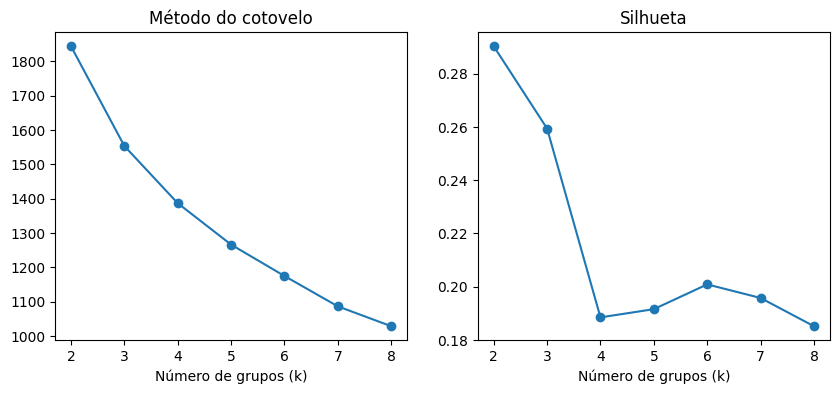

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

ks = range(2, 9)
inercias = []
silhuetas = []

for k in ks:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42)
    rotulos = modelo.fit_predict(X_pad)
    inercias.append(modelo.inertia_)
    silhuetas.append(silhouette_score(X_pad, rotulos))

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
eixos[0].plot(ks, inercias, marker="o")
eixos[0].set_title("Método do cotovelo")
eixos[0].set_xlabel("Número de grupos (k)")
eixos[1].plot(ks, silhuetas, marker="o")
eixos[1].set_title("Silhueta")
eixos[1].set_xlabel("Número de grupos (k)")
plt.show()

In [23]:
modelo = KMeans(n_clusters=3, n_init=10, random_state=42)
df["grupo"] = modelo.fit_predict(X_pad)

print(df["grupo"].value_counts().sort_index())

grupo
0     80
1    147
2    213
Name: count, dtype: int64


In [24]:
df.to_sql("clientes", conn, if_exists="replace", index=False)

perfil = """
SELECT grupo,
       COUNT(*) AS clientes,
       ROUND(AVG(Fresh)) AS fresh,
       ROUND(AVG(Milk)) AS milk,
       ROUND(AVG(Grocery)) AS grocery,
       ROUND(AVG(Frozen)) AS frozen,
       ROUND(AVG(Detergents_Paper)) AS detergents_paper,
       ROUND(AVG(Delicassen)) AS delicassen
FROM clientes
GROUP BY grupo
ORDER BY grupo
"""
pd.read_sql(perfil, conn)

,grupo,clientes,fresh,milk,grocery,frozen,detergents_paper,delicassen
0,0,80,2899.0,7136.0,12570.0,607.0,5554.0,783.0
1,1,147,17043.0,10560.0,13334.0,4133.0,4987.0,2847.0
2,2,213,11939.0,2006.0,2502.0,3266.0,424.0,891.0


In [25]:
pd.crosstab(df["grupo"], df["Channel"])

Channel,1,2
grupo,,
0,32,48
1,56,91
2,210,3


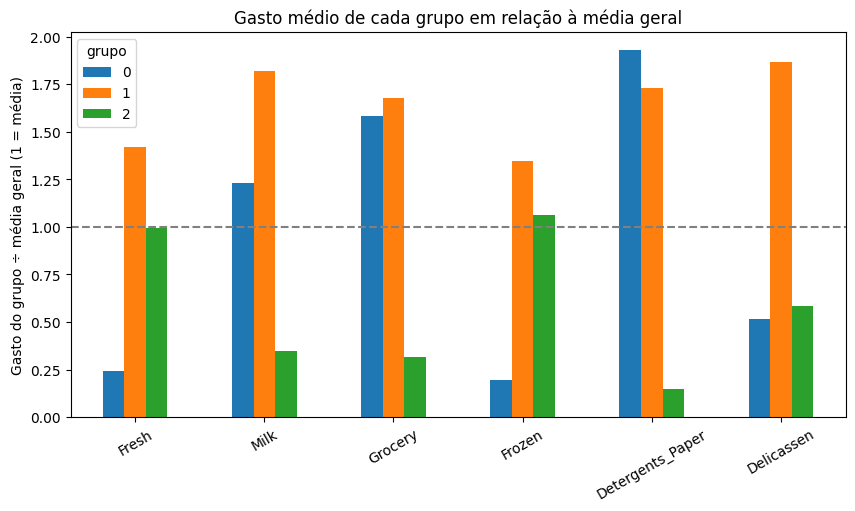

In [26]:
medias_geral = df[colunas].mean()
medias_grupo = df.groupby("grupo")[colunas].mean()
relativo = medias_grupo / medias_geral

relativo.T.plot(kind="bar", figsize=(10, 5))
plt.axhline(1, color="gray", linestyle="--")
plt.title("Gasto médio de cada grupo em relação à média geral")
plt.ylabel("Gasto do grupo ÷ média geral (1 = média)")
plt.xticks(rotation=30)
plt.show()

## Conclusões

### Os 3 grupos encontrados
- **Grupo 1, Grandes compradores (147 clientes, 33%):** gastam acima da média em todas as seis categorias, com destaque para delicatessen, leite, mercearia e limpeza (entre 1,7 e 1,9 vez a média).
- **Grupo 0, Mercado e limpeza (80 clientes, 18%):** compram muito em detergentes e papel (cerca de 1,9 vez a média) e em mercearia, mas quase nada de produtos frescos e congelados (cerca de 0,2 vez a média).
- **Grupo 2, Food service de frescos e congelados (213 clientes, 48%):** gastam na média em frescos e congelados, mas muito pouco em leite, mercearia e limpeza (entre 0,15 e 0,35 vez a média).

### O que descobri
- O grupo 2 tem 210 clientes do canal 1 (hotéis, restaurantes e cafés) e só 3 do varejo. O modelo, sem saber o canal, encontrou um grupo que se comporta como o food service.
- Os grupos 0 e 1 misturam os dois canais, com cerca de 60% de varejo em cada um. Ou seja, o agrupamento trouxe uma divisão diferente da coluna Channel.

### Ações sugeridas (são hipóteses)
- **Grandes compradores:** priorizar o relacionamento, com condições de volume e atendimento dedicado.
- **Mercado e limpeza:** testar ofertas de frescos e congelados, que eles compram pouco.
- **Food service:** testar pacotes de laticínios e produtos secos, que eles compram pouco.

### Limitações
- A silhueta ficou em cerca de 0,26, então os grupos se sobrepõem e os perfis são tendências, e não divisões rígidas.
- Com k = 2 a silhueta foi um pouco maior (cerca de 0,29). Escolhi k = 3 para ter mais detalhe nos perfis.
- Os valores estão em unidades monetárias, como informa a fonte, e não há dados de preço, margem nem de onde o cliente compra o restante. Por isso as ações precisam ser testadas antes de aplicadas.